In [2]:
import pandas as pd
from sklearn.impute import SimpleImputer
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay, auc, roc_auc_score, roc_curve, zero_one_loss
from sklearn.model_selection import GridSearchCV, LeaveOneOut, cross_val_score, cross_val_predict
import xgboost
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

The following code block completes 1(a).

In [4]:
train_df = pd.read_csv('aps_failure_training_set.csv', skiprows=20)
test_df = pd.read_csv('aps_failure_test_set.csv', skiprows=20)
train_df = train_df.replace({'na': np.nan})
test_df = test_df.replace({'na': np.nan})

The following code block completes 1(b)(i-v).

For 1(b)(i), common data imputation techniques include simple techniques such as filling missing values with the mean or median value of that column, or with a constant value such as 0; machine learning techniques such as kNN regression output or linear regression (for numerical data) output; and more complex techniques such as expectation maximization. For this assignment, I chose to use mean value imputation as the size of the dataset makes more complex techniques very computationally costly, and the complex nature of the dataset made constant value imputation inappropriate.

For 1(b)(iv), it is difficult to tell the significance of the features from the scatter plots as the features seem to be not very correlated with each other - we see a lot of horizontal and vertical lines in the scatter plot which tells us that one of the variables is nearly constant across its values.

For 1(b)(v), the training set has 59000 negative samples and 1000 positive samples, so it is very imbalanced.

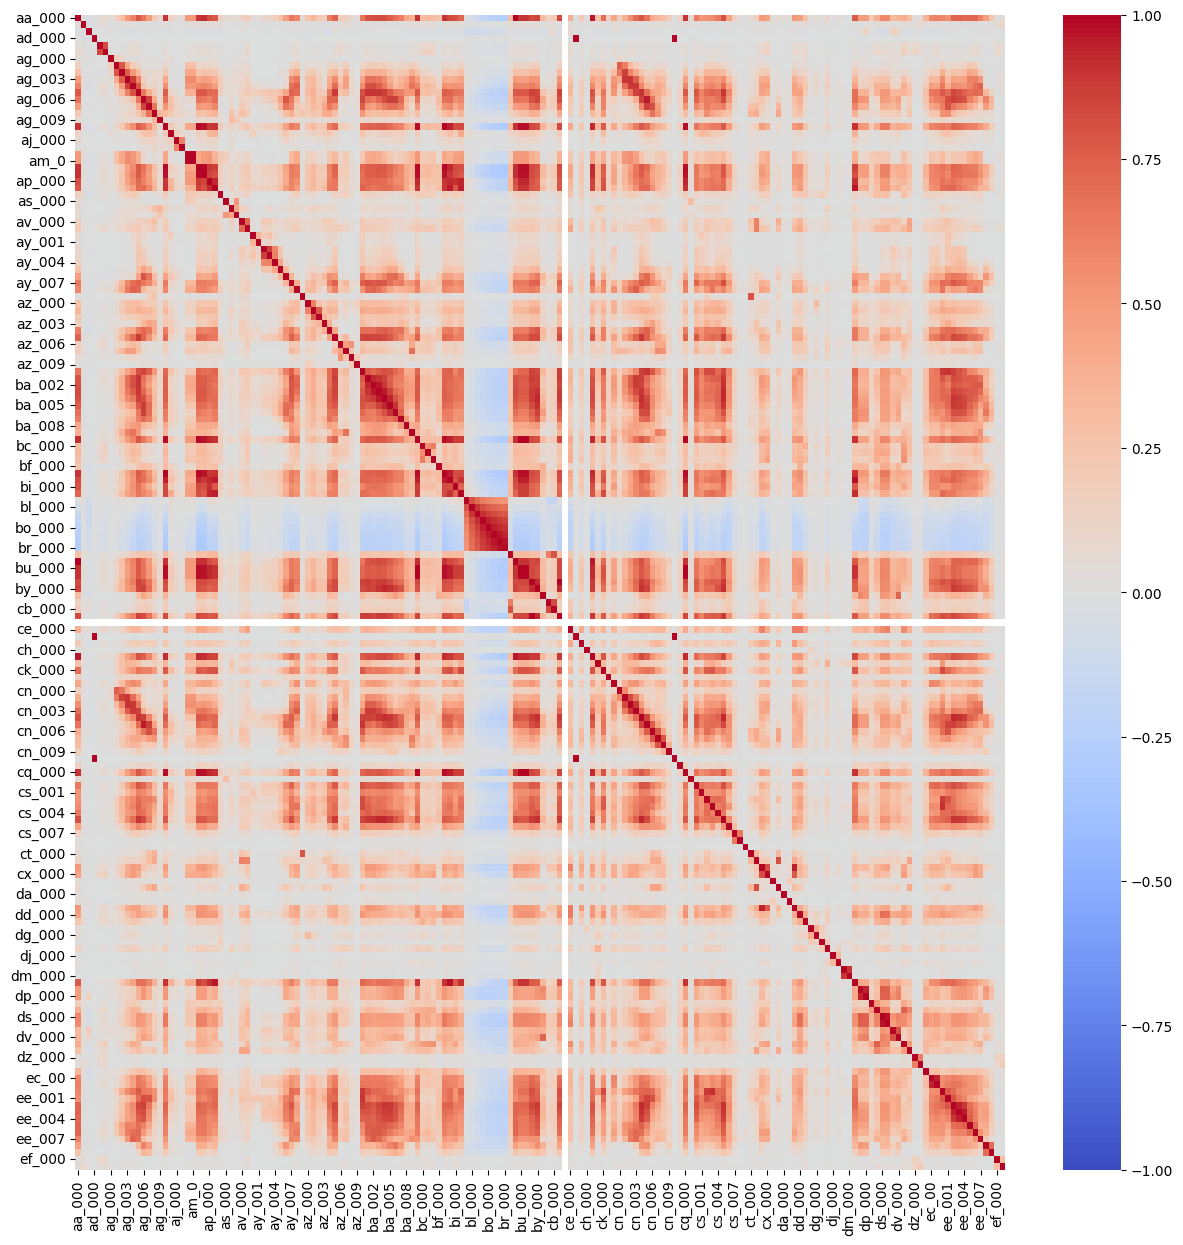

CV values: {'aa_000': np.float64(2.450937577943998), 'ab_000': np.float64(2.3283999870305188), 'ac_000': np.float64(2.169766523276902), 'ad_000': np.float64(183.84762036903817), 'ae_000': np.float64(23.19093666557794), 'af_000': np.float64(18.658921096017536), 'ag_000': np.float64(91.87856462936656), 'ag_001': np.float64(34.85495007772195), 'ag_002': np.float64(17.369143404889815), 'ag_003': np.float64(8.550049026704714), 'ag_004': np.float64(5.401478695421883), 'ag_005': np.float64(2.927092082425791), 'ag_006': np.float64(2.344927070337623), 'ag_007': np.float64(2.833484090935773), 'ag_008': np.float64(6.154583078551654), 'ag_009': np.float64(32.984351041336), 'ah_000': np.float64(2.300187248614353), 'ai_000': np.float64(18.01268174446174), 'aj_000': np.float64(43.80182238271909), 'ak_000': np.float64(74.52668795860689), 'al_000': np.float64(9.074370822656967), 'am_0': np.float64(9.05867160611329), 'an_000': np.float64(2.238796774380285), 'ao_000': np.float64(2.2601491168126637), 'ap_

<Figure size 1500x600 with 0 Axes>

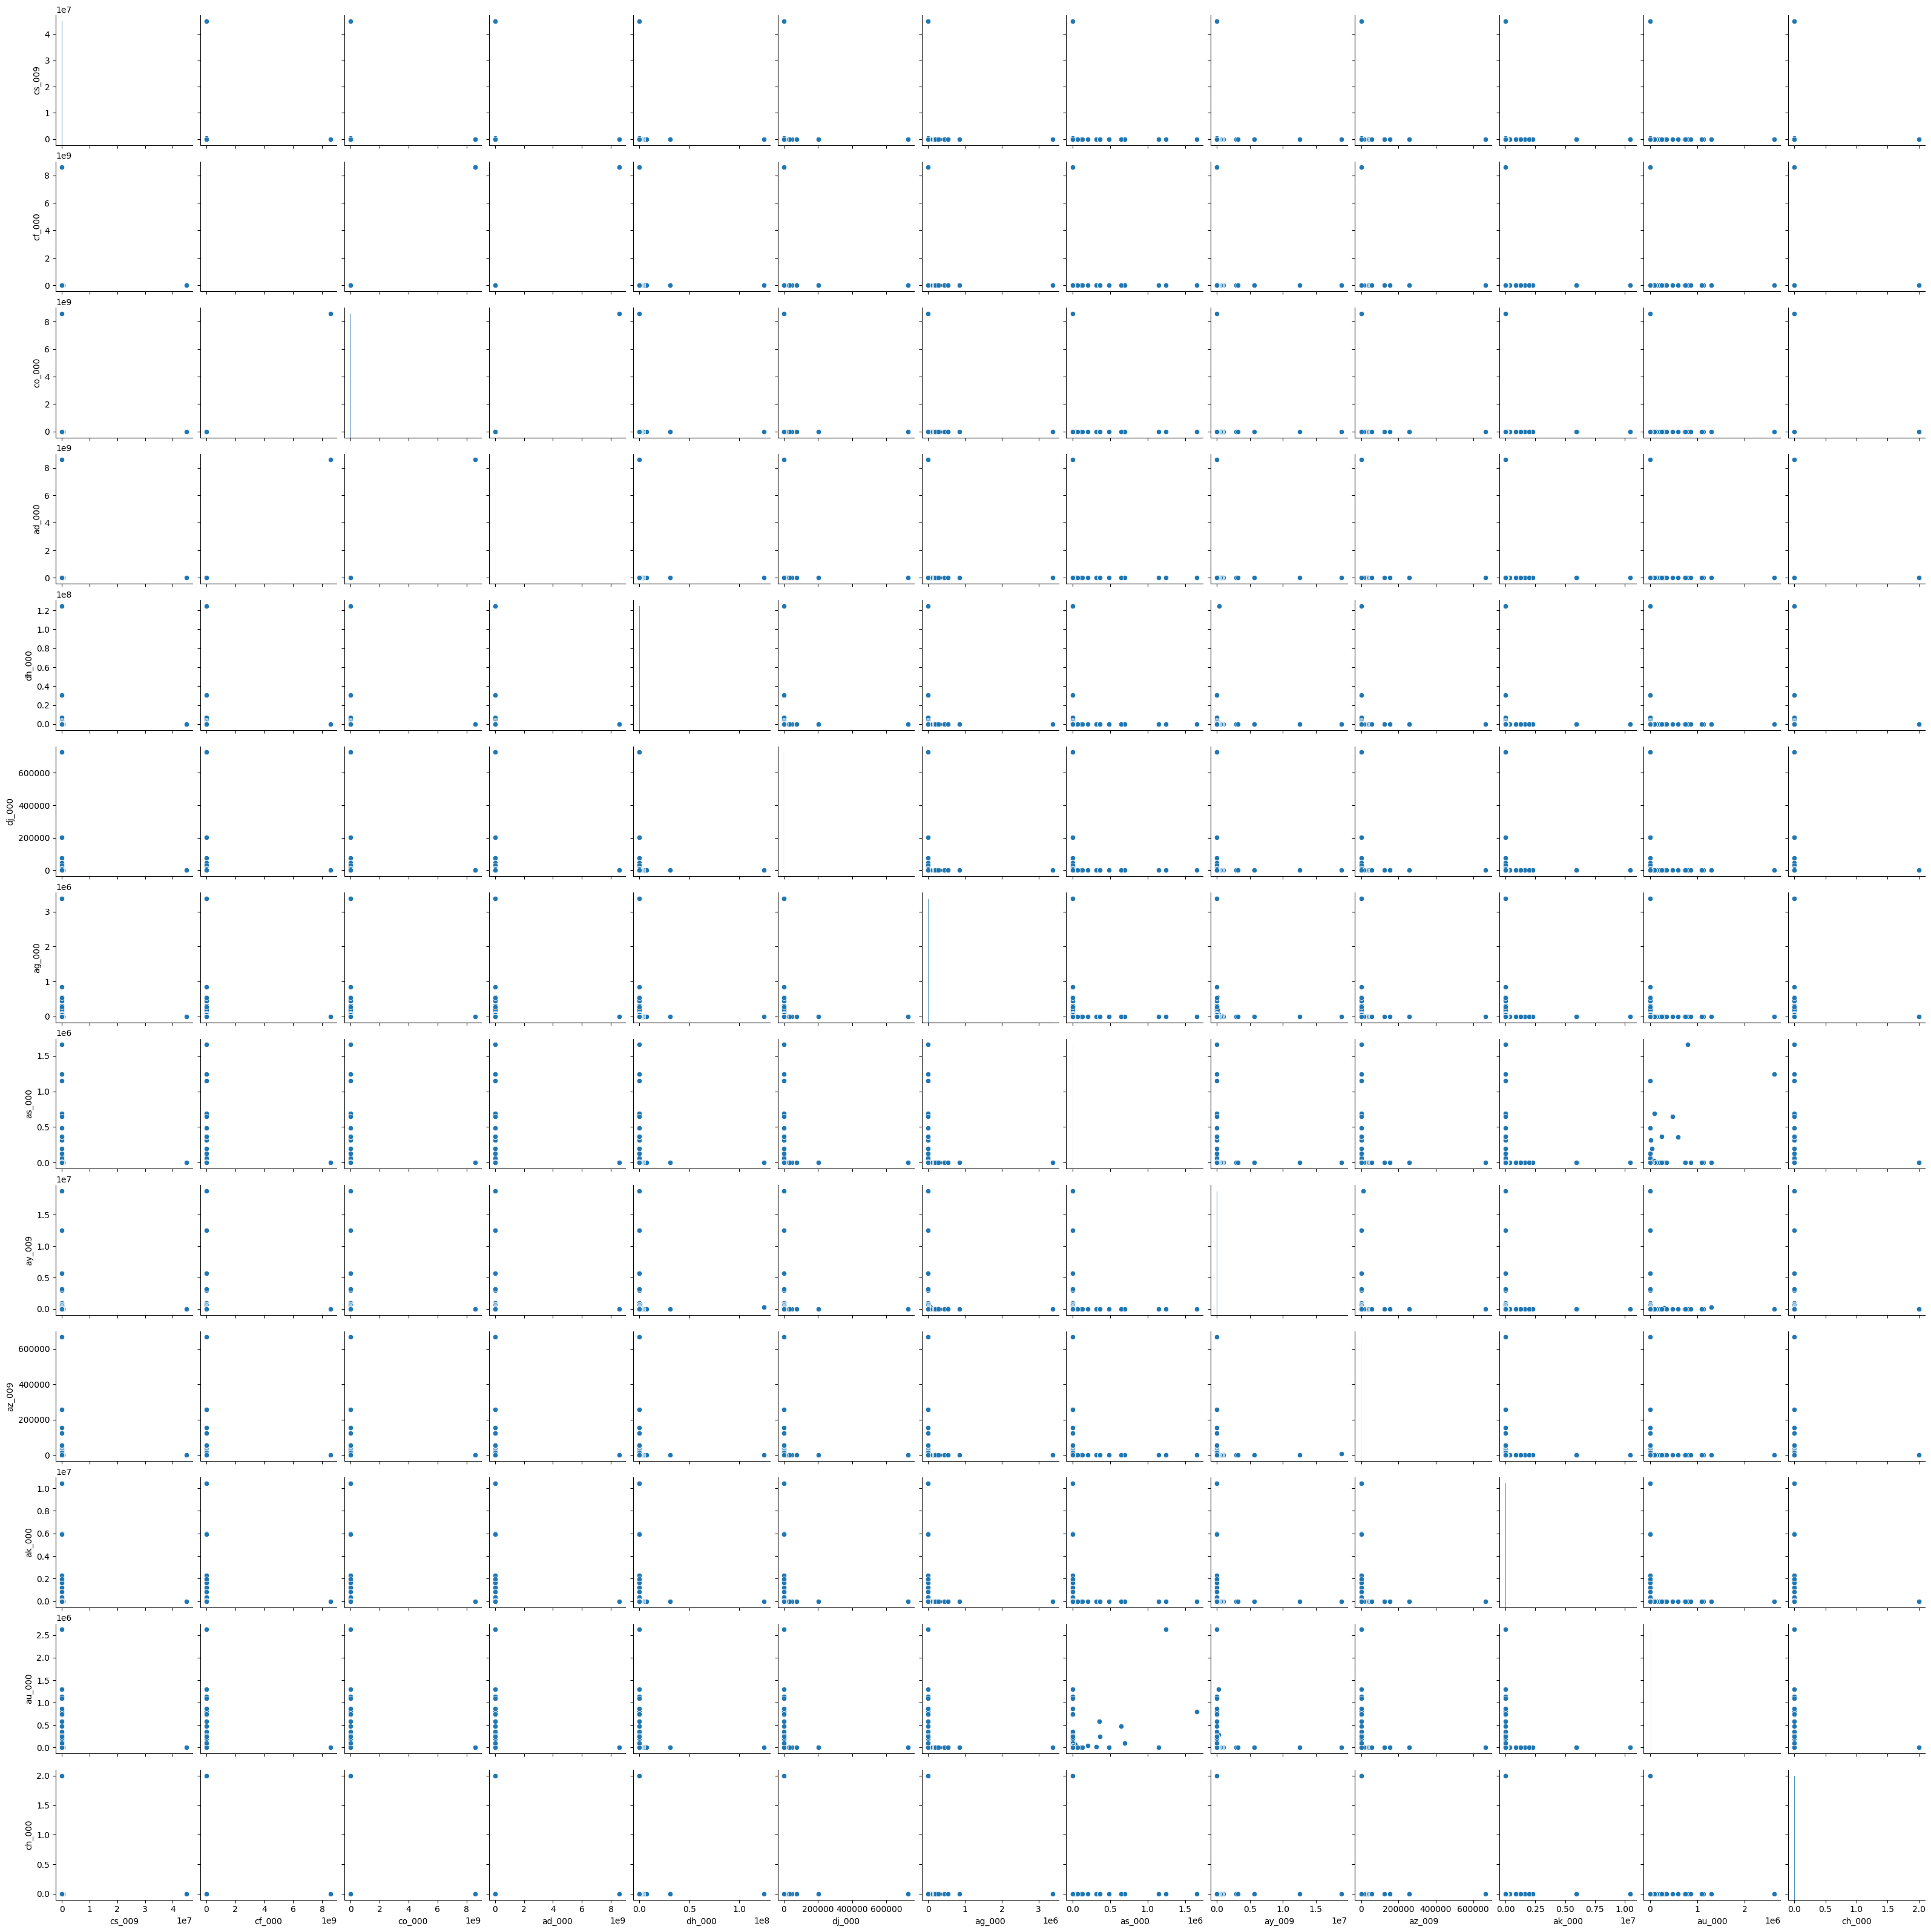

/tmp/ipykernel_579/1821816039.py:46: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


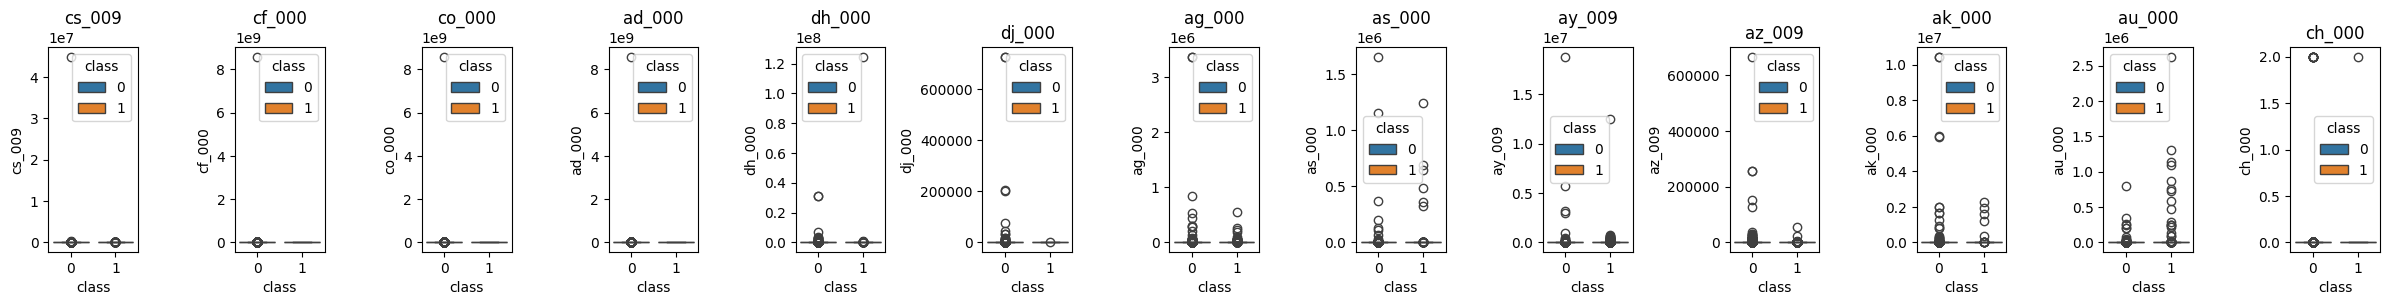

class
0    59000
1     1000
Name: count, dtype: int64


In [5]:
y_train = train_df['class']
X_train = train_df.drop(columns='class')
X_train_cols = X_train.columns
y_test = test_df['class']
X_test = test_df.drop(columns='class')
X_test_cols = X_test.columns
y_train = y_train.map({'neg': 0, 'pos': 1})
y_test = y_test.map({'neg': 0, 'pos': 1})

imp = SimpleImputer(strategy='mean', missing_values=np.nan)
X_train = imp.fit_transform(X_train)
X_test = imp.transform(X_test)
X_train = pd.DataFrame(X_train, columns=X_train_cols)
X_test = pd.DataFrame(X_test, columns=X_test_cols)


corr = X_train.corr()
plt.figure(figsize=(15, 15))
sns.heatmap(corr, cmap='coolwarm', vmin=-1, vmax=1)
plt.show()

cv_list = []
cv_dict = {} # for readability in the printout
for i in X_train.columns:
  cv = X_train[i].std()/X_train[i].mean()
  cv_list.append(cv)
  cv_dict[i] = cv
print(f'CV values: {cv_dict}')
best_cv_list = sorted(cv_list, reverse=True)
best_cv_list = best_cv_list[:13] # since floor of sqrt(170) is 13
best_cv_cols = [cv_list.index(i) for i in best_cv_list]

X_train_cvs = X_train.iloc[:, best_cv_cols]
X_train_cvs.columns = X_train.columns[best_cv_cols]

plt.figure(figsize=(15, 6))
sns.pairplot(X_train_cvs)
plt.show()

fig, axes = plt.subplots(1, 13, figsize=(24, 3), constrained_layout=True)
j = 0
for i in X_train_cvs.columns:
  sns.boxplot(x=y_train, y=X_train_cvs[i], ax=axes[j], hue=y_train)
  axes[j].set_title(i)
  j += 1
plt.tight_layout()
plt.show()

print(y_train.value_counts())

The following code block completes 1(c). The OOB error is about 0.006, while the test error is around 0.0075 - while both errors are very small, it is expected that the test error is larger than the training (OOB) error, which it is.

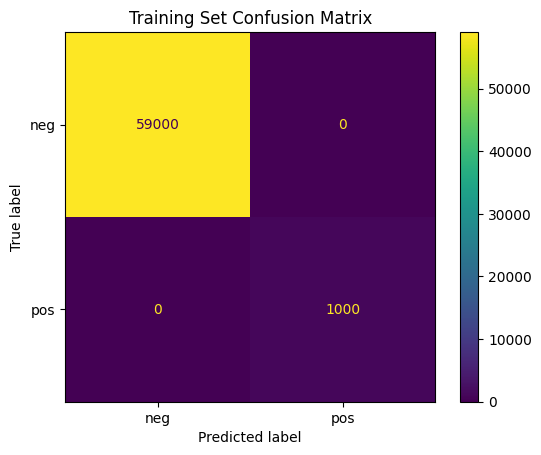

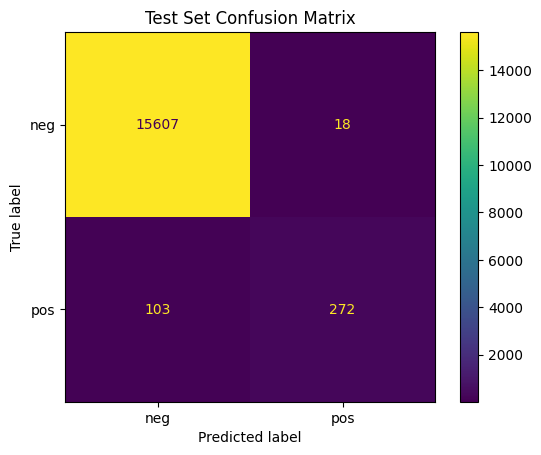

Training AUC score: 1.0


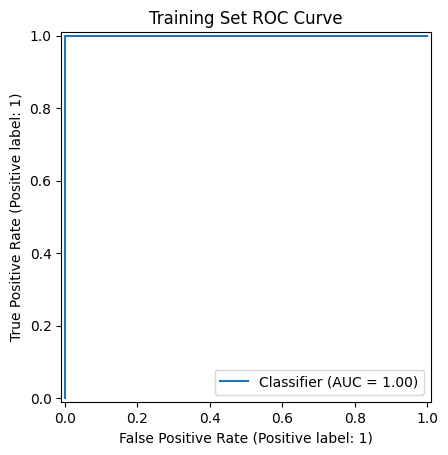

Test AUC score: 0.9928018773333332


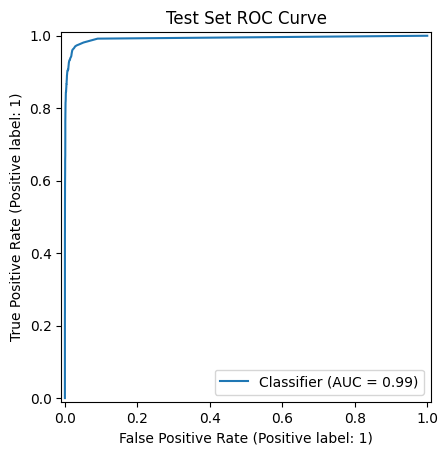

Train misclassification rate: 0.0
Test misclassification rate: 0.0075625000000000275
OOB Error: 0.006166666666666654


In [6]:
forest = RandomForestClassifier(oob_score=True)
forest.fit(X_train, y_train)
y_pred_train = forest.predict(X_train)
y_probs_train = forest.predict_proba(X_train)[:, 1]
y_pred_test = forest.predict(X_test)
y_probs_test = forest.predict_proba(X_test)[:, 1]

# confusion matrices
cm_train = confusion_matrix(y_train, y_pred_train)
cm_test = confusion_matrix(y_test, y_pred_test)
ConfusionMatrixDisplay(confusion_matrix=cm_train, display_labels=['neg', 'pos']).plot()
plt.title('Training Set Confusion Matrix')
plt.show()
ConfusionMatrixDisplay(confusion_matrix=cm_test, display_labels=['neg', 'pos']).plot()
plt.title('Test Set Confusion Matrix')
plt.show()

# ROC curves
fpr_train, tpr_train, thresholds_train = roc_curve(y_train, y_probs_train)
auc_train = roc_auc_score(y_train, y_probs_train)
print(f'Training AUC score: {auc_train}')
RocCurveDisplay.from_predictions(y_train, y_probs_train)
plt.title('Training Set ROC Curve')
plt.show()
fpr_test, tpr_test, thresholds_test = roc_curve(y_test, y_probs_test)
auc_test = roc_auc_score(y_test, y_probs_test)
print(f'Test AUC score: {auc_test}')
RocCurveDisplay.from_predictions(y_test, y_probs_test)
plt.title('Test Set ROC Curve')
plt.show()

# misclassification
mis_train = zero_one_loss(y_train, y_pred_train)
mis_test = zero_one_loss(y_test, y_pred_test)
print(f'Train misclassification rate: {mis_train}')
print(f'Test misclassification rate: {mis_test}')

print(f'OOB Error: {1 - forest.oob_score_}')

The following code block completes 1(d). Class imbalances in random forests can be addressed by using weighting on the classes (weighting penalties for the minority class more); using balanced bootstrap sampling for balanced samples that each tree in the random forest classifies on; resampling techniques such as SMOTE; or changing the decision threshold in favor of the minority class. I chose to use class weights as we will address resampling later on in the assignment, and I did not want to add an extra parameter to the CV for changing the decision threshold. The test error was around 0.01 and the OOB error was around 0.008; I am not sure why this model performed worse than the imbalanced version but I suspect that it has something to do with how even a balanced subsample can't be fully balanced because this dataset is so heavily skewed. That being said, the test error is still larger than the OOB error, which is expected.

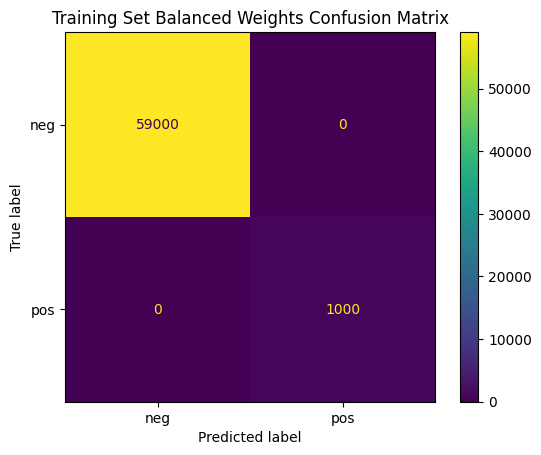

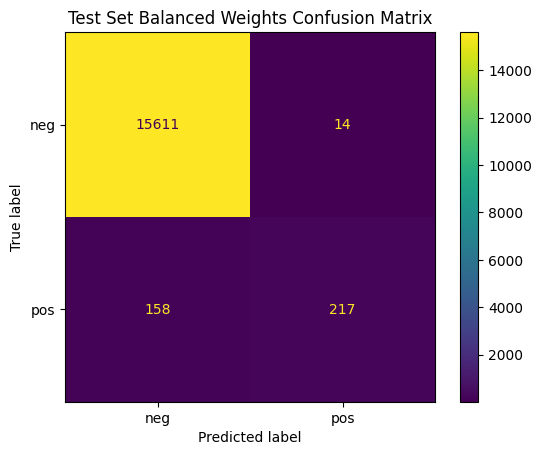

Training (balanced) AUC score: 1.0


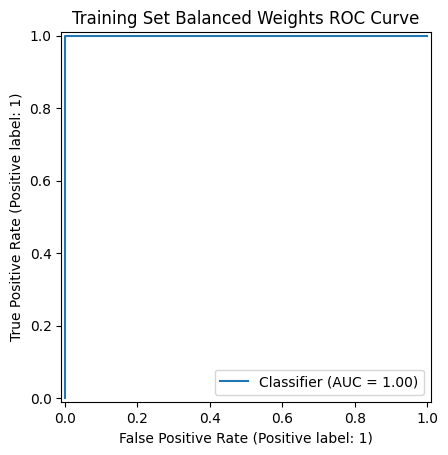

Test (balanced) AUC score: 0.9893782186666668


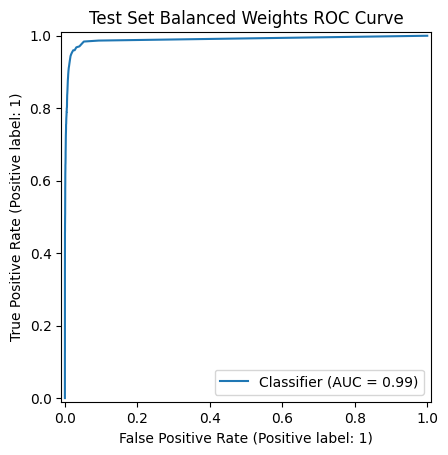

Train (balanced) misclassification rate: 0.0
Test (balanced) misclassification rate: 0.010750000000000037
OOB Error (balanced): 0.007750000000000035


In [7]:
balanced_forest = RandomForestClassifier(class_weight='balanced_subsample', oob_score=True)
balanced_forest.fit(X_train, y_train)
y_pred_train_bal = balanced_forest.predict(X_train)
y_probs_train_bal = balanced_forest.predict_proba(X_train)[:, 1]
y_pred_test_bal = balanced_forest.predict(X_test)
y_probs_test_bal = balanced_forest.predict_proba(X_test)[:, 1]

# confusion matrices
cm_train_bal = confusion_matrix(y_train, y_pred_train_bal)
cm_test_bal = confusion_matrix(y_test, y_pred_test_bal)
ConfusionMatrixDisplay(confusion_matrix=cm_train_bal, display_labels=['neg', 'pos']).plot()
plt.title('Training Set Balanced Weights Confusion Matrix')
plt.show()
ConfusionMatrixDisplay(confusion_matrix=cm_test_bal, display_labels=['neg', 'pos']).plot()
plt.title('Test Set Balanced Weights Confusion Matrix')
plt.show()

# ROC curves
fpr_train_bal, tpr_train_bal, thresholds_train_bal = roc_curve(y_train, y_probs_train_bal)
auc_train_bal = roc_auc_score(y_train, y_probs_train_bal)
print(f'Training (balanced) AUC score: {auc_train_bal}')
RocCurveDisplay.from_predictions(y_train, y_probs_train_bal)
plt.title('Training Set Balanced Weights ROC Curve')
plt.show()
fpr_test_bal, tpr_test_bal, thresholds_test_bal = roc_curve(y_test, y_probs_test_bal)
auc_test_bal = roc_auc_score(y_test, y_probs_test_bal)
print(f'Test (balanced) AUC score: {auc_test_bal}')
RocCurveDisplay.from_predictions(y_test, y_probs_test_bal)
plt.title('Test Set Balanced Weights ROC Curve')
plt.show()

# misclassification
mis_train_bal = zero_one_loss(y_train, y_pred_train_bal)
mis_test_bal = zero_one_loss(y_test, y_pred_test_bal)
print(f'Train (balanced) misclassification rate: {mis_train_bal}')
print(f'Test (balanced) misclassification rate: {mis_test_bal}')

print(f'OOB Error (balanced): {1 - balanced_forest.oob_score_}')

The following code block completes 1(e). The training error via 10-fold CV is about 0.005 while the test error is about 0.006. Therefore the imbalanced L1-penalized XGB model performed better than either random forest model, which is expected, and the test error is also higher than the training error, which is also expected. I only used 10-fold CV as the discussion on Piazza seemed to indicate that I could choose between 5-fold, 10-fold, and LOOCV.

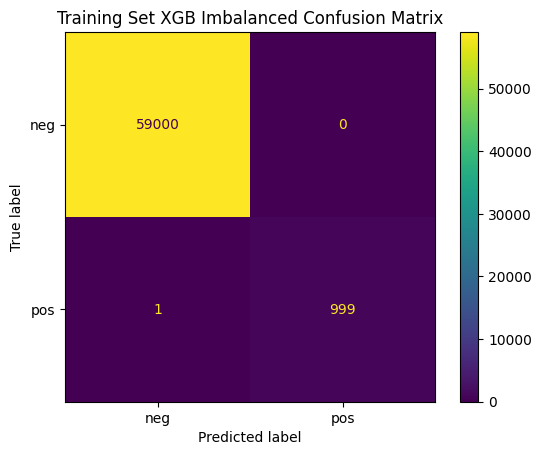

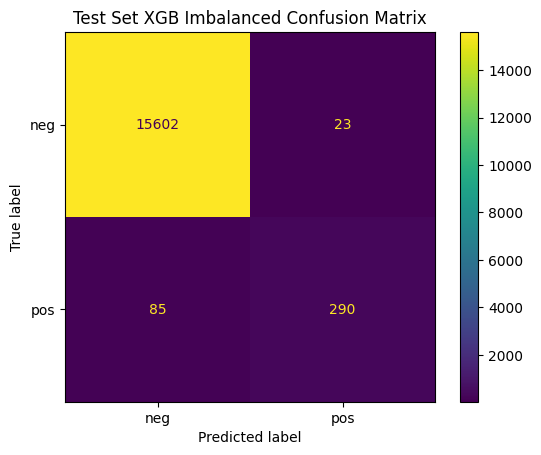

Training XGB Imbalanced AUC score: 0.9999988644067797


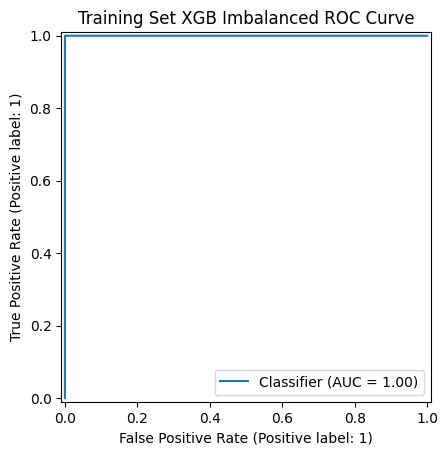

Test XGB Imbalanced AUC score: 0.9929133226666665


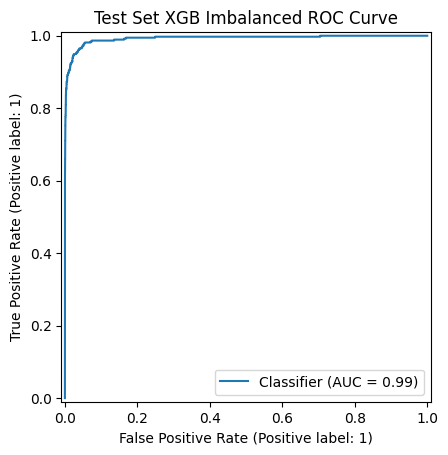

Train XGB Imbalanced misclassification rate (from 10-fold CV): 0.0058833333333333186
Test XGB Imbalanced misclassification rate: 0.006750000000000034


In [15]:
model = XGBClassifier(objective='binary:logistic')
param_grid = {'reg_alpha': [0.01, 0.1, 1.0, 10.0]}

cvalpha = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    scoring='accuracy',
    cv=5
)
cvalpha.fit(X_train, y_train)

best_alpha = cvalpha.best_params_['reg_alpha']
final_xgb = XGBClassifier(objective='binary:logistic', reg_alpha=best_alpha)

xgb_cv_score = cross_val_score(final_xgb, X_train, y_train, cv=10)
final_xgb.fit(X_train, y_train)
y_pred_train_xgb = final_xgb.predict(X_train)
y_probs_train_xgb = final_xgb.predict_proba(X_train)[:, 1]
y_pred_test_xgb = final_xgb.predict(X_test)
y_probs_test_xgb = final_xgb.predict_proba(X_test)[:, 1]

# confusion matrices
cm_train_xgb = confusion_matrix(y_train, y_pred_train_xgb)
cm_test_xgb = confusion_matrix(y_test, y_pred_test_xgb)
ConfusionMatrixDisplay(confusion_matrix=cm_train_xgb, display_labels=['neg', 'pos']).plot()
plt.title('Training Set XGB Imbalanced Confusion Matrix')
plt.show()
ConfusionMatrixDisplay(confusion_matrix=cm_test_xgb, display_labels=['neg', 'pos']).plot()
plt.title('Test Set XGB Imbalanced Confusion Matrix')
plt.show()

# ROC curves
fpr_train_xgb, tpr_train_xgb, thresholds_train_xgb = roc_curve(y_train, y_probs_train_xgb)
auc_train_xgb = roc_auc_score(y_train, y_probs_train_xgb)
print(f'Training XGB Imbalanced AUC score: {auc_train_xgb}')
RocCurveDisplay.from_predictions(y_train, y_probs_train_xgb)
plt.title('Training Set XGB Imbalanced ROC Curve')
plt.show()
fpr_test_xgb, tpr_test_xgb, thresholds_test_xgb = roc_curve(y_test, y_probs_test_xgb)
auc_test_xgb = roc_auc_score(y_test, y_probs_test_xgb)
print(f'Test XGB Imbalanced AUC score: {auc_test_xgb}')
RocCurveDisplay.from_predictions(y_test, y_probs_test_xgb)
plt.title('Test Set XGB Imbalanced ROC Curve')
plt.show()

# misclassification
mis_train_xgb = 1 - xgb_cv_score
mis_test_xgb = zero_one_loss(y_test, y_pred_test_xgb)
print(f'Train XGB Imbalanced misclassification rate (from 10-fold CV): {mis_train_xgb.mean()}')
print(f'Test XGB Imbalanced misclassification rate: {mis_test_xgb}')

The following code block completes 1(f). The training error via 10-fold CV is once again around 0.006 and the test error is once again around 0.007, so SMOTE did not really improve the performance of the L1-penalized XGB model. This could be because we did not use optimal SMOTE parameters or just because the model was already performind so well. For cross-validation on alpha, SMOTE happened only on the training set for each fold (the correct way of doing CV).

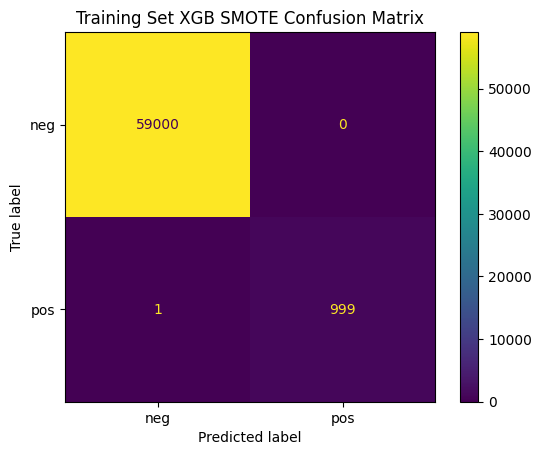

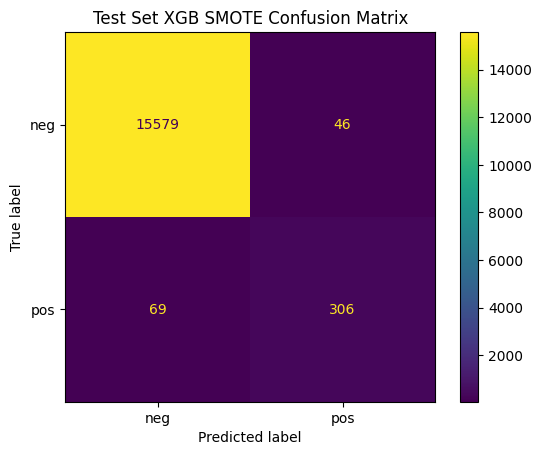

Training XGB SMOTE AUC score: 0.9999994322033898


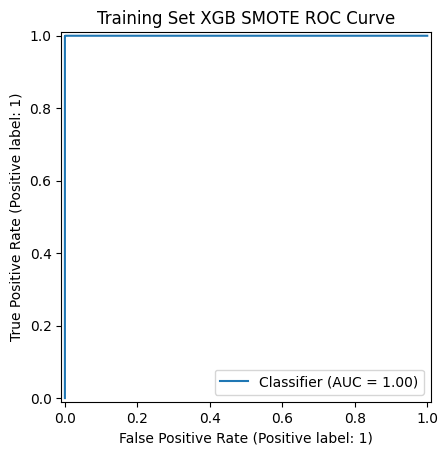

Test XGB SMOTE AUC score: 0.9940329813333333


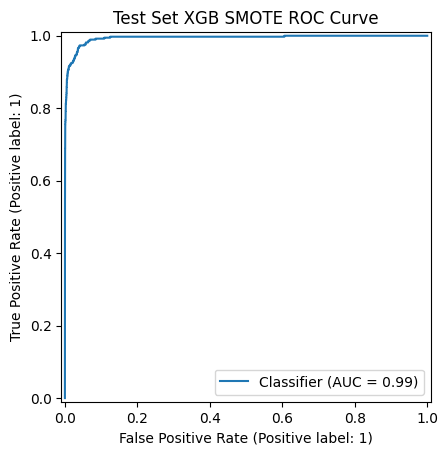

Train XGB SMOTE misclassification rate (from 10-fold CV): 0.006283333333333352
Test XGB SMOTE misclassification rate: 0.007187500000000013


In [16]:
pipe = Pipeline([
    ('smote', SMOTE()),
    ('xgb', XGBClassifier(objective='binary:logistic'))
])

param_grid = {'xgb__reg_alpha': [0.01, 0.1, 1.0, 10.0]}

cvsmote = GridSearchCV(
    estimator=pipe,
    param_grid=param_grid,
    scoring='accuracy',
    cv=5
)
cvsmote.fit(X_train, y_train)

smote_best_alpha = cvsmote.best_params_['xgb__reg_alpha']
xgb_smote = XGBClassifier(objective='binary:logistic', reg_alpha=smote_best_alpha)
pipe_new = Pipeline([
    ('smote', SMOTE()),
    ('xgb', xgb_smote)
])

smote_cv_score = cross_val_score(pipe_new, X_train, y_train)

final_smote = SMOTE()
X_train_smote, y_train_smote = final_smote.fit_resample(X_train, y_train)
xgb_smote.fit(X_train_smote, y_train_smote)

y_pred_train_smote = xgb_smote.predict(X_train)
y_probs_train_smote = xgb_smote.predict_proba(X_train)[:, 1]
y_pred_test_smote = xgb_smote.predict(X_test)
y_probs_test_smote = xgb_smote.predict_proba(X_test)[:, 1]

# confusion matrices
cm_train_smote = confusion_matrix(y_train, y_pred_train_smote)
cm_test_smote = confusion_matrix(y_test, y_pred_test_smote)
ConfusionMatrixDisplay(confusion_matrix=cm_train_smote, display_labels=['neg', 'pos']).plot()
plt.title('Training Set XGB SMOTE Confusion Matrix')
plt.show()
ConfusionMatrixDisplay(confusion_matrix=cm_test_smote, display_labels=['neg', 'pos']).plot()
plt.title('Test Set XGB SMOTE Confusion Matrix')
plt.show()

# ROC curves
fpr_train_smote, tpr_train_smote, thresholds_train_smote = roc_curve(y_train, y_probs_train_smote)
auc_train_smote = roc_auc_score(y_train, y_probs_train_smote)
print(f'Training XGB SMOTE AUC score: {auc_train_smote}')
RocCurveDisplay.from_predictions(y_train, y_probs_train_smote)
plt.title('Training Set XGB SMOTE ROC Curve')
plt.show()
fpr_test_smote, tpr_test_smote, thresholds_test_smote = roc_curve(y_test, y_probs_test_smote)
auc_test_smote = roc_auc_score(y_test, y_probs_test_smote)
print(f'Test XGB SMOTE AUC score: {auc_test_smote}')
RocCurveDisplay.from_predictions(y_test, y_probs_test_smote)
plt.title('Test Set XGB SMOTE ROC Curve')
plt.show()

# misclassification
mis_train_smote = 1 - smote_cv_score
mis_test_smote = zero_one_loss(y_test, y_pred_test_smote)
print(f'Train XGB SMOTE misclassification rate (from 10-fold CV): {mis_train_smote.mean()}')
print(f'Test XGB SMOTE misclassification rate: {mis_test_smote}')